# 02 — Du brut aux données de modélisation (nettoyage, qualité, variables)

**But.** Montrer comment les décisions de l'EDA (`01_EDA.ipynb`) sont appliquées, vérifiées, puis transformées en
**variables** pour les modèles. Ce notebook **lit** les sorties du pipeline : il ne recalcule rien et n'entraîne
aucun modèle.

| Étape du pipeline | Code | Sortie lue ici |
|---|---|---|
| `ingest` : nettoyage, une règle = une fonction | `src/parkinson_mm/data/` | `reports/tables/clean/journal_nettoyage.csv` |
| `validate` : contrats de qualité bloquants | `src/parkinson_mm/data/validation/` | `reports/validation/*.json` |
| `split` : séparation par patient | `src/parkinson_mm/data/split.py` | `data/processed/splits.csv` |
| `features` / `horizons` : variables, passé seulement | `src/parkinson_mm/features/` | `data/processed/pd_*_samples.csv` |

Pour régénérer ces fichiers : `python scripts/prepare_data.py` puis `python scripts/run_horizons.py --stage data`
(quelques secondes à quelques minutes).

**Plan.** 1. Journal de nettoyage · 2. Contrats de qualité · 3. Jeu longitudinal final · 4. Séparation par patient ·
5. Variables sans regarder le futur · 6. Quelles variables pour quels modèles ? · 7. Prétraitement appris sur le
train · 8. Synthèse : des données aux modèles

In [1]:
import os, sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path(os.environ.get("PPMI_PROJECT_ROOT", Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from parkinson_mm import visualization as viz
from parkinson_mm.utils.config import load_config

cfg = load_config(ROOT / "params.yaml")
PROC, REP = cfg.path("processed"), cfg.path("reports")
viz.set_style(); pd.set_option("display.max_colwidth", 110); pd.set_option("display.width", 180)

needed = [REP / "tables/clean/journal_nettoyage.csv", PROC / "pd_longitudinal.csv", PROC / "splits.csv",
          PROC / "pd_next_visit_samples.csv", PROC / "pd_multi_horizon_samples.csv"]
missing = [p.relative_to(ROOT) for p in needed if not p.exists()]
print("Fichiers manquants : lancer d'abord le pipeline." if missing else "Toutes les sorties du pipeline sont là.",
      *missing, sep="\n")

Toutes les sorties du pipeline sont là.


## 1. Le journal de nettoyage

**Pourquoi.** Chaque règle de nettoyage laisse une trace : nombre de lignes et de patients avant et après, et
**pourquoi** la règle existe. Un nettoyage non tracé n'est pas vérifiable.

In [2]:
journal = pd.read_csv(REP / "tables/clean/journal_nettoyage.csv")
journal["retirées"] = journal["lignes_avant"] - journal["lignes_apres"]
journal[["etape", "lignes_avant", "lignes_apres", "retirées", "patients_apres", "justification"]]

,etape,lignes_avant,lignes_apres,retirées,patients_apres,justification
0,Cohorte PD,9304,2257,7047,2257,Question limitée à la maladie de Parkinson (témoins/prodromaux exclus).
1,Statut d'inclusion valide,2257,1744,513,1744,Screen-failed / refus : jamais suivis.
2,Visites à distance exclues,21869,20075,1794,1743,Visites R## : pas d'examen moteur possible.
3,NP3 valide,20075,18215,1860,1741,101 = non évaluable ; proratisation si <= 3 items manquants.
4,1 examen par visite,18215,13847,4368,1741,"Doublons ON/OFF : écart ~10 pts ; OFF prioritaire, état en covariable."
5,1 visite par mois,13847,13683,164,1741,Visite programmée prioritaire.
6,Mesures avant BL exclues,13683,13206,477,1741,Le temps 0 est la baseline.
7,"DaTSCAN analysés, ligand 123I",3631,3609,22,1397,Le TRODAT n'est pas sur la même échelle SBR.
8,Dataset final,13206,13206,0,1741,"Après fusion clinique, imagerie (as-of) et variables patient."


**Lecture.** La plus grande perte de **patients** vient du statut d'inclusion (patients jamais suivis). La plus
grande perte de **lignes** vient de la règle « un examen par visite » : ce sont des doublons OFF/ON ramenés à une
ligne, pas des patients perdus. Aucune valeur extrême n'est supprimée : les hausses de plus de 25 points en moins
d'un an sont seulement **signalées** (`jump_flag`).

## 2. Les contrats de qualité

**Pourquoi.** Un contrat est une liste de contrôles automatiques. S'il échoue, le pipeline **s'arrête** au lieu de
produire un résultat faux. Trois moments sont contrôlés : les données brutes, le jeu nettoyé, et les échantillons de
modélisation (absence de fuite).

In [3]:
rows = []
for stage in ("raw", "clean", "samples", "horizons"):
    path = REP / "validation" / f"{stage}.json"
    if path.exists():
        r = json.loads(path.read_text(encoding="utf-8"))
        rows.append({"contrat": stage, "réussi": r["passed"], "contrôles": len(r["checks"]),
                     "erreurs": r["errors"], "avertissements": r["warnings"]})
display(pd.DataFrame(rows))
samples_contract = json.loads((REP / "validation" / "samples.json").read_text(encoding="utf-8"))
pd.DataFrame(samples_contract["checks"])      # contrôles anti-fuite des échantillons

,contrat,réussi,contrôles,erreurs,avertissements
0,raw,True,22,0,0
1,clean,True,10,0,0
2,samples,True,5,0,0
3,horizons,True,5,0,0


,check,ok,severity
0,aucun patient à la fois en dev et en test,True,error
1,un patient = un seul pli,True,error
2,cible définie,True,error
3,écart entre visites positif,True,error
4,historique calculé sur le passé uniquement,True,error


**Lecture.** Tous les contrats passent. Le contrat des échantillons vérifie en particulier qu'**aucun patient
n'est à la fois en développement et en test**, et que l'historique de chaque visite est calculé sur le **passé
seulement**.

## 3. Le jeu longitudinal final

Une ligne = un patient à une visite (au plus une par mois), sur un axe de temps continu.

In [4]:
long = pd.read_csv(PROC / "pd_longitudinal.csv", parse_dates=["visit_date"])
patients = pd.read_csv(PROC / "pd_patients.csv")
n = patients.n_visits
pd.Series({
    "patients": long.PATNO.nunique(), "visites": len(long),
    "patients avec au moins 2 visites": int((n >= 2).sum()),
    "visites par patient, médiane [IQR]": f"{n.median():.0f} [{n.quantile(.25):.0f}–{n.quantile(.75):.0f}]",
    "suivi médian (années)": round(patients.followup_years.median(), 1),
    "examens OFF / sans traitement / ON (%)": " / ".join(f"{100 * long.med_state.eq(s).mean():.0f}"
                                                         for s in ["OFF", "untreated", "ON"]),
    "scores proratisés (≤ 3 items manquants)": int(long.np3_imputed.sum()),
    "hausses > 25 points signalées (gardées)": int(long.jump_flag.sum()),
}).to_frame("valeur")

,valeur
patients,1741
visites,13206
patients avec au moins 2 visites,1512
"visites par patient, médiane [IQR]",6 [4–11]
suivi médian (années),3.1
examens OFF / sans traitement / ON (%),40 / 32 / 28
scores proratisés (≤ 3 items manquants),128
hausses > 25 points signalées (gardées),172


In [5]:
# Valeurs manquantes : au niveau de la visite (mesures répétées) et du patient (mesures uniques)
visite = [c for c in ["np3", "nhy", "updrs1", "updrs2", "updrs4", "schwab", "ledd", "moca", "ess", "gds",
                      "scopa_aut", "stai", "sbr_putamen"] if c in long]
patient = [c for c in ["age_bl", "male", "disease_dur_bl", "lrrk2", "gba", "apoe4", "prs", "sbr_caudate_bl",
                       "mri_putamen", "csf_ab42_40", "csf_ptau181", "plasma_nfl", "plasma_gfap"] if c in patients]
pd.concat([long[visite].isna().mean().mul(100).round(1).to_frame("% manquant").assign(niveau="visite"),
           patients[patient].isna().mean().mul(100).round(1).to_frame("% manquant").assign(niveau="patient")])

,% manquant,niveau
np3,0.0,visite
nhy,0.1,visite
updrs1,0.5,visite
updrs2,0.5,visite
updrs4,30.4,visite
schwab,0.2,visite
ledd,0.2,visite
moca,37.2,visite
ess,31.7,visite
gds,32.0,visite


**Lecture.** La cible (`np3`) est complète par construction. Les manquants des autres variables sont
**structurels** (sous-études, échelles annuelles). Ils ne sont pas imputés ici : l'imputation se fait plus tard,
dans chaque pli d'entraînement (section 7).

### 3.1 D'où viennent ces manquants : les règles des autres colonnes

**Pourquoi.** Le journal (section 1) suit surtout la cible. Les autres colonnes ont aussi leurs règles, appliquées par le
code de `src/parkinson_mm/data/`. Une seule idée les relie : **une valeur impossible devient manquante, mais la visite
est gardée**. On ne perd pas un examen moteur valide parce que le questionnaire de sommeil est incomplet.

| Colonne(s) | Règle | Pourquoi | Code |
|---|---|---|---|
| UPDRS I, II, IV, Schwab & England | valeur hors de l'échelle (ex. UPDRS II > 52, Schwab > 100) → manquante | une valeur impossible est une erreur de saisie | `data/clinical.py` |
| Hoehn & Yahr | hors de 0–5 → manquant | même raison | `data/updrs3.py` |
| MoCA | hors de 0–30 → manquant | même raison | `data/nonmotor.py` |
| Epworth, GDS-15, SCOPA-AUT, STAI | somme des items **seulement si tous sont remplis**, sinon manquant ; items inversés (GDS, STAI) retournés ; SCOPA : code 9 (« utilise une sonde ») compté 3 | une somme d'items incomplète sous-estime le score | `data/nonmotor.py` |
| Âge à la visite | manquant → âge à l'inclusion + temps écoulé | c'est un calcul exact, pas une imputation | `data/clinical.py` |
| LEDD (dose de traitement) | 0 si non traité ; **manquante** si le patient est traité mais absent du journal des médicaments ; > 4 000 mg/j → manquante | « traité, dose inconnue » n'est pas « 0 mg » | `data/treatment.py` |
| Années d'études | hors de 0–30 → manquant | erreur de saisie | `data/patient.py` |
| LRRK2, GBA, APOE ε4 | 1 = porteur, 0 = non porteur, **vide = non testé** | « non testé » n'est pas « non porteur » | `data/patient.py` |
| Biomarqueurs | « < 8 » (sous la limite de détection) → 4 ; « > 1997 » → 1997 ; un seul laboratoire par marqueur | garder l'information au lieu d'un manquant ; ne pas mélanger des échelles | `data/biology.py` |

Les deux cellules suivantes **vérifient** ces règles sur le jeu final.

In [6]:
# Chaque échelle reste dans ses bornes (min et max observés sur le jeu final)
bornes = {"nhy": (0, 5), "updrs1": (0, 52), "updrs2": (0, 52), "updrs4": (0, 24), "schwab": (0, 100),
          "moca": (0, 30), "ess": (0, 24), "gds": (0, 15), "scopa_aut": (0, 63), "stai": (40, 160), "ledd": (0, 4000)}
pd.DataFrame([{"colonne": c, "bornes": f"{lo}–{hi}", "min observé": long[c].min(), "max observé": long[c].max(),
               "% manquant": round(100 * long[c].isna().mean(), 1),
               "dans les bornes": bool(long[c].dropna().between(lo, hi).all())}
              for c, (lo, hi) in bornes.items() if c in long]).set_index("colonne")

,bornes,min observé,max observé,% manquant,dans les bornes
colonne,,,,,
nhy,0–5,0.0,5.0,0.1,True
updrs1,0–52,0.0,38.0,0.5,True
updrs2,0–52,0.0,49.0,0.5,True
updrs4,0–24,0.0,19.0,30.4,True
schwab,0–100,0.0,100.0,0.2,True
moca,0–30,0.0,30.0,37.2,True
ess,0–24,0.0,24.0,31.7,True
gds,0–15,0.0,15.0,32.0,True
scopa_aut,0–63,0.0,55.0,31.9,True


In [7]:
# « Non testé » n'est pas « non porteur » : trois valeurs possibles pour chaque gène (patients)
gen = {g: patients[g].map({1.0: "porteur (1)", 0.0: "non porteur (0)"}).fillna("non testé (vide)").value_counts()
       for g in ["lrrk2", "gba", "apoe4"] if g in patients}
display(pd.DataFrame(gen).fillna(0).astype(int))

# LEDD : 0 mg si non traité ; vide si traité mais dose inconnue (visites)
etat = long["on_treatment"].map({0.0: "non traité", 1.0: "traité"}).fillna("statut inconnu")
dose = pd.Series(np.select([long["ledd"].isna(), long["ledd"].eq(0)], ["vide (inconnue)", "0 mg"], "> 0 mg"),
                 index=long.index, name="LEDD")
pd.crosstab(etat.rename("traitement"), dose, margins=True, margins_name="total")

,lrrk2,gba,apoe4
non porteur (0),1172,1042,1040
non testé (vide),379,579,387
porteur (1),190,120,314


LEDD,0 mg,> 0 mg,vide (inconnue),total
traitement,,,,
non traité,3233,989,0,4222
statut inconnu,1,2,0,3
traité,138,8815,28,8981
total,3372,9806,28,13206


**Lecture.** Toutes les échelles restent dans leurs bornes : aucune valeur impossible n'arrive aux modèles. Le statut
génétique a bien trois valeurs : pour LRRK2, 190 porteurs, 1 172 non porteurs et 379 **non testés**, qui restent vides
au lieu d'être comptés comme non porteurs. Pour la LEDD, seules 28 visites de patients traités ont une dose inconnue.
Les deux sources ne concordent pas toujours : 989 visites notées « non traité » à l'examen ont une dose > 0 dans le
journal des médicaments, et 138 visites « traité » une dose de 0 (probablement des dates au mois près, ou un traitement
commencé ou arrêté autour de la visite). Les deux variables sont gardées telles quelles, sans corriger l'une par
l'autre : c'est une limite connue.

## 4. La séparation par patient

**Pourquoi.** Les visites d'un même patient se ressemblent (notebook 01). On sépare donc les
**patients**, une fois pour toutes, avant de construire les variables.

In [8]:
splits = pd.read_csv(PROC / "splits.csv")
display(splits.groupby("split").agg(patients=("PATNO", "nunique")).T)
display(splits[splits.split == "dev"].fold.value_counts().sort_index().rename("patients par pli").to_frame().T)

dev, test = set(splits.PATNO[splits.split == "dev"]), set(splits.PATNO[splits.split == "test"])
assert not dev & test, "Un patient est dans les deux ensembles !"
print("Aucun patient commun entre développement et test.")

split,dev,test
patients,1209,303


fold,0,1,2,3,4
patients par pli,242,242,242,242,241


Aucun patient commun entre développement et test.


In [9]:
# Les deux groupes se ressemblent-ils ? Moyennes à l'inclusion
p = patients.merge(splits, on="PATNO")
cols = [c for c in ["age_bl", "male", "np3_bl", "nhy_bl", "disease_dur_bl", "followup_years"] if c in p]
p.groupby("split")[cols].mean().T.round(2)

split,dev,test
age_bl,63.14,62.56
male,0.61,0.62
np3_bl,22.54,22.31
nhy_bl,1.70,1.71
disease_dur_bl,1.43,1.22
followup_years,5.02,5.06


**Lecture.** Aucun patient n'est partagé, et les deux groupes ont des moyennes proches (âge, sexe, score à l'inclusion,
durée de maladie, durée de suivi). Le test (environ 300 patients) n'est utilisé qu'**une seule fois**, à la fin. Les
5 plis du développement servent à la validation croisée **groupée par patient**.

## 5. Construire les variables

### 5.1 Les variables construites à partir des colonnes brutes (feature engineering)

**Pourquoi.** Une colonne brute de PPMI n'est pas toujours utilisable telle quelle : 33 items séparés, des dates, une
liste de médicaments, des volumes en mm³. Le code en tire des variables qui ont un **sens clinique**. Chacune est
calculée avec les informations de la visite elle-même ou des visites d'avant.

| Variable | Construite à partir de | Comment | Code |
|---|---|---|---|
| `np3` | 33 items du MDS-UPDRS III | total fourni, sinon somme des items, sinon proratisé (≤ 3 items manquants) | `data/updrs3.py` |
| `tremor3`, `pigd3`, `rigid3`, `brady3` | items de la partie III | somme des items de chaque domaine, seulement si tous sont présents | `data/updrs3.py` |
| `asym3` | items côté droit / côté gauche | écart absolu droite − gauche : la maladie touche souvent un côté d'abord | `data/updrs3.py` |
| `tremor_score`, `pigd_score` | items des parties II et III | moyenne des items de tremblement / de marche et d'équilibre (Stebbins 2013) | `data/clinical.py` |
| `med_state`, `med_off`, `med_on`, `on_treatment` | `PDTRTMNT`, `PDSTATE` | non traité / OFF / ON, puis deux colonnes 0/1 pour les modèles | `data/updrs3.py`, `features/history.py` |
| `time_years` | dates `MM/YYYY` | années depuis la baseline : un temps continu, pas un numéro de visite | `data/visits.py` |
| `disease_dur_years` | date du diagnostic | années depuis le diagnostic, à chaque visite | `data/treatment.py` |
| `ledd` | journal des médicaments | somme des doses actives à la date de la visite (inhibiteurs de la COMT : facteur appliqué à la lévodopa) | `data/treatment.py` |
| `sbr_*` | DaTSCAN | dernier scan **déjà fait** à chaque visite ; rapport putamen / caudé, asymétrie | `data/datscan.py` |
| `mri_*` | volumes FreeSurfer | volume ÷ volume intracrânien × 1 000 (‰) : retire l'effet de la taille de la tête | `data/mri.py` |
| `plasma_nfl`, `plasma_gfap`, `csf_ptau181` | dosages | logarithme : valeurs très asymétriques | `data/biology.py` |
| `csf_ab42_40` | Aβ42 et Aβ40 du LCR | rapport des deux, plus robuste qu'Aβ42 seul | `data/biology.py` |
| `lrrk2`, `gba`, `apoe4` | résultats génétiques | 1 / 0 / vide (voir section 3.1) | `data/patient.py` |

In [10]:
# Les variables construites, résumées sur le jeu final : médiane [IQR] et part de manquants
def resume(df, cols, niveau):
    return pd.DataFrame([{"variable": c, "niveau": niveau, "médiane": round(df[c].median(), 2),
                          "IQR": f"[{df[c].quantile(.25):.2f} ; {df[c].quantile(.75):.2f}]",
                          "% manquant": round(100 * df[c].isna().mean(), 1)} for c in cols if c in df])

pd.concat([resume(long, ["tremor3", "pigd3", "rigid3", "brady3", "asym3", "tremor_score", "pigd_score",
                         "time_years", "disease_dur_years", "ledd", "sbr_putamen"], "visite"),
           resume(patients, ["mri_putamen", "mri_cortex", "plasma_nfl", "csf_ptau181", "csf_ab42_40"], "patient")]
          ).set_index("variable")

,niveau,médiane,IQR,% manquant
variable,,,,
tremor3,visite,4.00,[1.00 ; 8.00],0.1
pigd3,visite,1.00,[0.00 ; 1.00],0.6
rigid3,visite,4.00,[2.00 ; 7.00],0.1
brady3,visite,11.00,[7.00 ; 16.00],0.3
asym3,visite,6.00,[3.00 ; 9.00],0.4
tremor_score,visite,0.45,[0.18 ; 0.82],0.4
pigd_score,visite,0.40,[0.20 ; 0.60],0.9
time_years,visite,2.00,[0.58 ; 4.00],0.0
disease_dur_years,visite,3.08,[1.58 ; 5.58],0.0


**Lecture.** Les variables tirées de l'examen moteur sont presque complètes (≤ 1 % de manquants) ; celles de l'imagerie
et de la biologie ne concernent qu'une partie des patients (22 à 56 % de manquants), d'où leur traitement à part
(section 3.1). Exemples de lecture : la moitié des visites ont une asymétrie droite − gauche d'au moins
6 points ; le putamen représente environ 5,6 ‰ du volume intracrânien.

### 5.2 L'historique d'un patient (sans regarder le futur)

**Règle anti-fuite.** À la visite *i*, une variable ne peut utiliser que les visites **≤ i**. Exemple sur un patient
anonymisé (« patient A ») :

In [ ]:
nxt = pd.read_csv(PROC / "pd_next_visit_samples.csv")
counts = nxt[nxt.split == "dev"].PATNO.value_counts()
example = counts[counts >= 5].index[0]                       # un patient du dev avec au moins 5 visites
cols = ["time_years", "np3", "med_state", "np3_prev", "np3_slope_hist", "np3_mean_hist", "n_prior",
        "gap_months", "target_state", "y_next"]
nxt[nxt.PATNO == example][cols].head(6).round(2).assign(patient="A").set_index("patient")

**Lecture.**

* `np3_prev` est le score de la visite précédente, `np3_slope_hist` la pente des visites passées (à partir de 2
  visites), `np3_mean_hist` leur moyenne, `n_prior` le nombre de visites avant celle-ci.
* `gap_months` (délai jusqu'à la visite suivante) et `target_state` (état prévu : OFF, ON ou sans traitement) sont
  **connus à l'avance** par le protocole : ce ne sont pas des fuites.
* `y_next` est la **cible** : elle n'est jamais utilisée comme entrée.

Pour l'imagerie, la même règle s'applique : à chaque visite, on prend le **dernier DaTSCAN déjà réalisé**.

### 5.3 Ce qu'il faut prédire

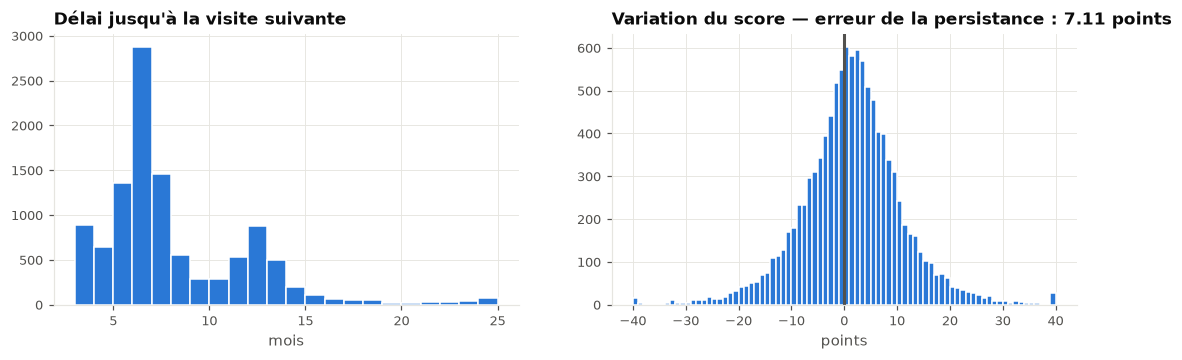

,12 mois,24 mois,36 mois
paires,9160,6866,5217
patients,1376,1256,1015


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
axes[0].hist(nxt.gap_months, bins=range(3, 26), color=viz.C["blue"], edgecolor="white")
axes[0].set_title("Délai jusqu'à la visite suivante"); axes[0].set_xlabel("mois")
axes[1].hist(nxt.delta.clip(-40, 40), bins=80, color=viz.C["blue"], edgecolor="white"); axes[1].axvline(0, color=viz.INK2)
axes[1].set_title(f"Variation du score — erreur de la persistance : {nxt.delta.abs().mean():.2f} points")
axes[1].set_xlabel("points"); viz.save(fig, REP / "figures" / "clean", "cible_delta"); plt.show()

hz = pd.read_csv(PROC / "pd_multi_horizon_samples.csv")
pd.DataFrame({f"{h} mois": {"paires": int(hz[f"y_{h}"].notna().sum()),
                            "patients": int(hz.loc[hz[f"y_{h}"].notna(), "PATNO"].nunique())}
              for h in cfg.horizons.months})

**Lecture.** En moyenne, le score change peu d'une visite à l'autre, mais la variation est très dispersée : la règle
« le score ne change pas » (**persistance**) se trompe déjà d'environ 7 points. C'est la référence que tout modèle doit
battre. Pour le long terme (sprint 2), chaque visite d'origine est reliée à la mesure la plus proche de 12, 24 et
36 mois (± 3 mois) ; il y a moins de paires à 36 mois, car beaucoup de patients ont un suivi court.

## 6. Quelles variables pour quels modèles ? (sélection de variables)

### 6.1 Les groupes de variables

In [13]:
from parkinson_mm.features import groups as G
from parkinson_mm.features.horizons import SUMMARY
pd.DataFrame([
    ("Clinique par visite (séquences)", G.STEP_CLIN, "tous les modèles appris ; séquences du GRU et du GRU-D"),
    ("Résumé de l'historique", SUMMARY, "LightGBM, MLP, GRU-D (variables fixes)"),
    ("Conditions de la visite à prédire", ["gap", "état prévu OFF/ON/sans traitement"], "tous les modèles"),
    ("Démographie", G.DEMO, "tous les modèles ; ajustement des modèles mixtes (âge, sexe)"),
    ("Biologie", G.BIO, "objectif 3 (facteurs)"),
    ("DaTSCAN", G.DAT, "objectif 3 (facteurs)"),
    ("IRM", G.MRI, "objectif 3 (facteurs)"),
    ("Génétique", G.GEN, "objectif 3 (facteurs)"),
], columns=["groupe", "variables", "utilisé par"]).assign(n=lambda d: d.variables.map(len))

,groupe,variables,utilisé par,n
0,Clinique par visite (séquences),"[np3, nhy, updrs1, updrs2, updrs4, schwab, tremor_score, pigd_score, rigid3, brady3, asym3, on_treatment, ...",tous les modèles appris ; séquences du GRU et du GRU-D,23
1,Résumé de l'historique,"[np3_prev, np3_slope_hist, np3_mean_hist, n_prior]","LightGBM, MLP, GRU-D (variables fixes)",4
2,Conditions de la visite à prédire,"[gap, état prévu OFF/ON/sans traitement]",tous les modèles,2
3,Démographie,"[male, age_bl, EDUCYRS, ANYFAMPD]","tous les modèles ; ajustement des modèles mixtes (âge, sexe)",4
4,Biologie,"[csf_abeta42, csf_ab42_40, csf_ptau181, csf_asyn, plasma_nfl, plasma_gfap]",objectif 3 (facteurs),6
5,DaTSCAN,"[sbr_striatum, sbr_putamen, sbr_putamen_min, sbr_caudate, sbr_put_caud_ratio, sbr_put_asym, sbr_age_months]",objectif 3 (facteurs),7
6,IRM,"[mri_putamen, mri_caudate, mri_pallidum, mri_thalamus, mri_hippocampus, mri_lat_ventricles, mri_brainstem,...",objectif 3 (facteurs),9
7,Génétique,"[lrrk2, gba, apoe4, PATHVAR_COUNT, prs]",objectif 3 (facteurs),5


### 6.2 Pourquoi pas de sélection automatique ?

Les variables sont choisies **a priori**, pas par un algorithme de sélection :

* **Connaissance du domaine et EDA** : on garde les échelles cliniques non redondantes (notebook 01) et leur historique.
* **Fuite.** Une sélection faite sur toutes les données avant la validation croisée utilise l'information des plis de
  validation : les résultats seraient trop optimistes.
* **Petit nombre de patients** (environ 1 200 en développement) par rapport au nombre de variables possibles.
* **Interprétation.** Chaque variable doit avoir un sens clinique pour un jury et pour un neurologue.
* **Modalités** (imagerie, biologie, génétique) : pas données aux 4 modèles de l'objectif 2 (beaucoup de manquants,
  ADR-0015) ; étudiées facteur par facteur à l'objectif 3.

## 7. Le prétraitement est appris sur le train seulement

**Pourquoi.** Remplacer une valeur manquante par la médiane, ou standardiser une variable, demande des statistiques
(médiane, moyenne, écart-type). Si on les calcule sur toutes les données, l'information du test fuit dans
l'entraînement. On les calcule donc **dans chaque pli d'entraînement**, puis on les applique telles quelles.

In [14]:
from parkinson_mm.features.preprocessing import TabularPreprocessor
cols = [c for c in ["np3", "nhy", "moca", "ledd", "np3_slope_hist", "age_bl"] if c in nxt]
train = nxt[(nxt.split == "dev") & (nxt.fold != 0)]
held_out = nxt[(nxt.split == "dev") & (nxt.fold == 0)]
pre = TabularPreprocessor(cols).fit(train)                 # appris sur les plis 1 à 4 seulement
z = pre.transform(held_out)                                # appliqué tel quel au pli 0
print(f"Entrée du modèle : {z.shape[1]} colonnes = {len(cols)} variables standardisées "
      f"+ {len(pre.flagged_)} indicateurs « valeur manquante » ({', '.join(pre.flagged_)})")
pd.DataFrame({"médiane (train)": pre.median_, "moyenne (train)": pre.mean_, "écart-type (train)": pre.std_}).round(2)

Entrée du modèle : 10 colonnes = 6 variables standardisées + 4 indicateurs « valeur manquante » (nhy, moca, ledd, np3_slope_hist)


,médiane (train),moyenne (train),écart-type (train)
np3,24.00,26.10,12.59
nhy,2.00,1.88,0.55
moca,27.00,26.79,2.43
ledd,310.00,439.75,464.88
np3_slope_hist,1.52,1.84,8.21
age_bl,62.90,61.91,9.64


**Lecture.** Chaque variable avec des manquants reçoit un **indicateur** (1 = la valeur manquait) : le modèle sait
qu'une valeur a été remplacée. Les z-scores sont bornés à ±5 pour qu'une valeur extrême ne sature pas un réseau. Le
GRU-D va plus loin : il reçoit, pour chaque mesure, un **masque** et le **temps écoulé** depuis la dernière mesure.

## 8. Synthèse : des données aux modèles

| Ce que montrent les données | Choix dans les modèles |
|---|---|
| Visites irrégulières, nombre de visites variable | temps continu ; écart de temps entre visites en entrée des modèles |
| Patients très différents (pentes) | une pente propre à chaque patient (objectifs 1 et 3) |
| Visites d'un même patient dépendantes | split et validation croisée par patient |
| Effet ON / OFF d'environ 10 points | état de l'examen en variable ; état prévu en entrée |
| Score bruité d'une visite à l'autre | référence de persistance |
| Valeurs impossibles (hors échelle, questionnaire incomplet) | manquantes, la visite est gardée (section 3.1) |
| Manquants structurels | indicateurs de manquant ; aucune imputation de la cible |
| Modalités rares (imagerie, biologie, génétique) | facteur par facteur (objectif 3), sur les seuls patients qui ont la mesure |

Ces données alimentent les objectifs 1 à 3 et le sprint 5 (résultats dans MLflow) ; le notebook `03` étudie la robustesse du modèle retenu.